# 08 — Repair v9's care boundary and test it on matched rows

v10 preserves observed symptoms before later care, excludes explicit post-event background,
and keeps all structured predictors and labels intact. It is retrospective report classification.
The policy was fixed before these CPU scores. **These are development TF-IDF diagnostics, not E5/TAR.**

Local outputs below come from the actual supplied data. For a fresh Colab CPU run, upload
`vaers_v10_tools.zip` when prompted; it contains our tools, not the official benchmark.
Use a separate CPU runtime while GPU notebooks continue. Raw yearly ZIPs and v9 remain on Drive.


In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess
try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    drive.mount('/content/drive')
    PROJECT = Path('/content/vaers-v10-tools')
    bundle = Path('/content/vaers_v10_tools.zip')
    if not bundle.exists():
        print('Upload the prepared vaers_v10_tools.zip')
        files.upload()
    import zipfile
    PROJECT.mkdir(exist_ok=True)
    with zipfile.ZipFile(bundle) as z:
        for member in z.infolist():
            destination = (PROJECT / member.filename).resolve()
            if not destination.is_relative_to(PROJECT.resolve()) or (member.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError('Unsafe bundle member')
        z.extractall(PROJECT)
    HOME_DATA = Path('/content/drive/MyDrive/text-tabular-research-2')
    BASE = HOME_DATA / 'candidates/build8/vaers_v9/vaers_v9.csv'
    RAW = sorted((HOME_DATA / 'vaers_raw').glob('*VAERSData.zip'))
    BUILD_DIR = HOME_DATA / 'candidates/build9'
    RESULT_ZIP = HOME_DATA / 'benchmark-results/20b24baf903ae7ac/tennis_diagnostic_20b24baf903ae7ac_results.zip'
    DIAGNOSTIC_DIR = HOME_DATA / 'diagnostics/v10_care_boundary2'
else:
    PROJECT = Path.cwd()
    if not (PROJECT / 'research/scripts/vaers/refine_v9.py').exists():
        PROJECT = PROJECT / 'text-tabular-research-2'
    BASE = Path.home() / 'Downloads/vaers_v9-20261017T080754Z-1-001.zip'
    RAW = [Path.home() / f'Downloads/{year}VAERSData.zip' for year in [2019, 2023, 2024]]
    BUILD_DIR = PROJECT.parent / 'vaers-research-cache/derived/build9'
    RESULT_ZIP = Path.home() / 'Downloads/tennis_diagnostic_20b24baf903ae7ac_results.zip'
    DIAGNOSTIC_DIR = PROJECT.parent / 'vaers-research-cache/diagnostics/v10_care_boundary2'
sys.path.insert(0, str(PROJECT))
from research.scripts.vaers import refine_v9 as rv, diagnose_refinement as diagnostic
print('policy:', rv.POLICY_VERSION, '| source sha256:', hashlib.sha256(Path(rv.__file__).read_bytes()).hexdigest())
print('parent:', BASE)


policy: care-boundary-2 | source sha256: 7968c033d6c2ecf1afd1113ed32e0ec25ad181f335f3d5921f6a1877252ad6e4
parent: /Users/dimabshara/Downloads/vaers_v9-20261017T080754Z-1-001.zip


In [2]:
test = subprocess.run([sys.executable, '-m', 'unittest', 'research.scripts.vaers.test_refine_v9', '-q'],
                      cwd=PROJECT, capture_output=True, text=True)
print(test.stderr)
if test.returncode:
    raise RuntimeError('Refinement regression tests failed')
if (BUILD_DIR / 'build_summary.json').exists():
    build = json.loads((BUILD_DIR / 'build_summary.json').read_text())
    paths = {v: str(BUILD_DIR / f'vaers_{v}/vaers_{v}.csv') for v in ['v10', 'v10_matched', 'v9_control']}
    for v, path in paths.items():
        s = json.loads(Path(path).with_name('schema.json').read_text())
        assert hashlib.sha256(Path(path).read_bytes()).hexdigest() == s['csv_sha256']
        assert s['provenance']['refinement_sha256'] == hashlib.sha256(Path(rv.__file__).read_bytes()).hexdigest(), 'Policy changed; select a new build folder'
    counts = build['counts']
    print('Verified existing frozen build; no files overwritten')
else:
    paths, counts = rv.build(BASE, RAW, BUILD_DIR)
import pandas as pd
from IPython.display import display
display(pd.DataFrame(counts['by_label']).rename(index={'parent':'Parent rows', 'retained':'Retained rows', 'removed':'Excluded rows'}))
print('Total:', counts['parent_rows'], '->', counts['kept_rows'], 'rows')
print('Changed excerpts:', counts['excerpt_changed'], '| changed backgrounds:', counts['background_changed'])


----------------------------------------------------------------------
Ran 15 tests in 0.114s

OK

Verified existing frozen build; no files overwritten
Total: 20136 -> 19832 rows
Changed excerpts: 543 | changed backgrounds: 1575


,0,1
Parent rows,15102,5034
Retained rows,14929,4903
Excluded rows,173,131


## Actual text changes

`v10_matched` keeps all parent IDs for sensitivity analysis, including censored placeholders.
`v10` excludes uninformative excerpts and explicitly post-event background.
`v9_control` retains the original v9 text on exactly the v10 rows: this is the matched GPU control.


In [3]:
parent, _, _ = rv.read_base(BASE)
parent = parent.set_index('report_id')
fixed = pd.read_csv(paths['v10_matched'], dtype={'report_id': str}).set_index('report_id')
eligible = set(pd.read_csv(paths['v10'], dtype={'report_id': str}).report_id)
examples = []
for rid in ['809322', '820772', '2554658', '2760881', '831877', '854775']:
    if rid in parent.index:
        examples.append({'ID': rid, 'v9 excerpt': parent.at[rid, 'narrative_onset'],
                         'v10 excerpt': fixed.at[rid, 'narrative_onset'], 'eligible': rid in eligible})
with pd.option_context('display.max_colwidth', 180):
    display(pd.DataFrame(examples))


,ID,v9 excerpt,v10 excerpt,eligible
0,809322,"Extreme inflammatory response resulting in hyperglycemia and hemolytic anemia requiring blood transfusion x 2. Pt's symptoms included dizzy, lightheaded, blurred vision, fatigue.",Extreme inflammatory response resulting in hyperglycemia and hemolytic anemia,True
1,820772,"vomiting, lethargy, diarrhea which became bloody diarrhea- intussusception requiring surgery.","vomiting, lethargy, diarrhea which became bloody diarrhea- intussusception",True
2,2554658,Shortness of breath that resulted in triple bypass surgery,Shortness of breath,True
3,2760881,"Two weeks after receiving the third dose of the of the vaccine, I woke up two weeks later for work one morning and I was unable to walk normal on my left foot. I underwent surg...","Two weeks after receiving the third dose of the of the vaccine, I woke up two weeks later for work one morning and I was unable to walk normal on my left foot.",True
4,831877,Child was given the Hep B at birth. Child was born healthy and other had zero pain meds or delivery assistance from medication. Natural healthy vaginal delivery.,Child was given the Hep B at birth. Child was born healthy and other had zero pain meds or delivery assistance from medication. Natural healthy vaginal delivery.,False
5,854775,- : 14:00.,none reported,False


## Matched CPU diagnostics — 32 small fits

The all-parent comparison isolates text changes while allowing censoring placeholders.
The eligible-row comparison fits both policies on identical restricted training/test rows.
All fitted preprocessing uses training rows only. These are previously inspected development folds.


In [4]:
if (DIAGNOSTIC_DIR / 'summary.json').exists():
    result = json.loads((DIAGNOSTIC_DIR / 'summary.json').read_text())
    for v, path in paths.items():
        assert result['plan']['data_sha256'][v] == hashlib.sha256(Path(path).read_bytes()).hexdigest()
    assert hashlib.sha256((DIAGNOSTIC_DIR / 'diagnostic_source.py').read_bytes()).hexdigest() == result['plan']['diagnostic_code_sha256']
    print('Loaded the recorded CPU run; data and saved execution source verified')
else:
    result = diagnostic.run(BASE, BUILD_DIR, RESULT_ZIP, DIAGNOSTIC_DIR)
scores = pd.DataFrame(result['scores'])
means = scores[scores.protocol != 'negative_control'].groupby(['protocol', 'variant', 'condition']).auroc.mean().unstack()
for protocol in means.index.get_level_values(0).unique():
    means.loc[(protocol, 'v10'), 'structured'] = means.loc[(protocol, 'v9'), 'structured']
means['joint_signal_proxy'] = means.joint - means[['structured', 'text']].max(axis=1)
display(means.round(6))
display(pd.DataFrame(result['quality_checks'].items(), columns=['Implemented check', 'Result']))
display(pd.DataFrame(result['selection_flags']).T)


Loaded the recorded CPU run; data and saved execution source verified


condition                      joint  structured      text  joint_signal_proxy
protocol           variant                                                    
all_parent_rows    v10      0.862096    0.784353  0.855441            0.006656
                   v9       0.862230    0.784353  0.855521            0.006709
same_eligible_rows v10      0.862416    0.785097  0.855411            0.007005
                   v9       0.862532    0.785097  0.855604            0.006928

,Implemented check,Result
0,protected_fields_unchanged,True
1,candidate_control_same_ordered_ids,True
2,remaining_extra_care_matches_in_candidate_exce...,0
3,remaining_explicit_post_event_matches_in_candi...,0


,audit_only_flag_auroc,orientation_free_auroc
post_event_background,0.506754,0.506754
eligible,0.492716,0.507284
excerpt_changed,0.503476,0.503476


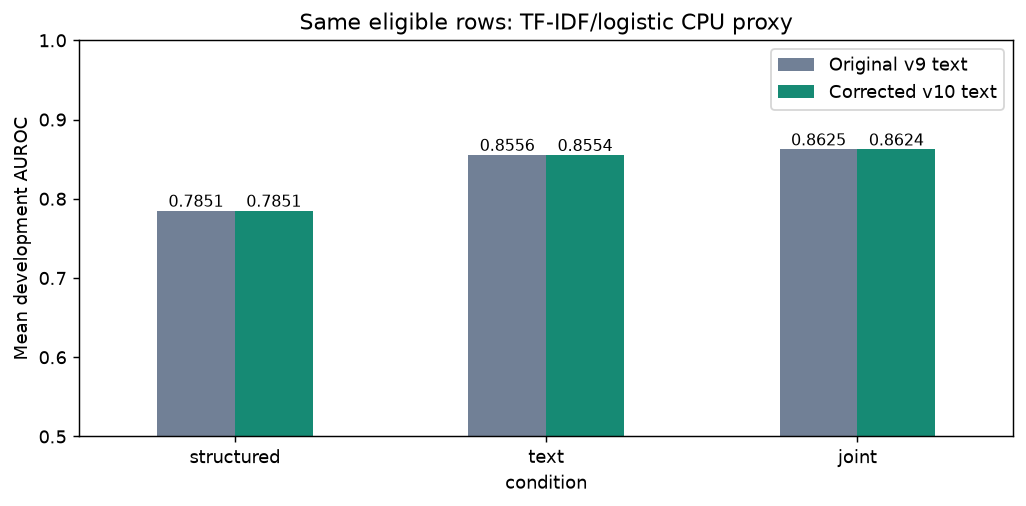

,variant,auroc,n_train,n_test
10,label_permutation,0.496606,9848,1970
11,text_permutation,0.773172,9848,1970


In [5]:
import matplotlib.pyplot as plt
common = means.loc['same_eligible_rows', ['structured', 'text', 'joint']].reindex(['v9', 'v10'])
ax = common.T.plot.bar(figsize=(8, 4), ylim=(0.5, 1.0), rot=0, color=['#718096', '#168a74'])
ax.set_ylabel('Mean development AUROC')
ax.set_title('Same eligible rows: TF-IDF/logistic CPU proxy')
ax.legend(['Original v9 text', 'Corrected v10 text'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', fontsize=9)
plt.tight_layout()
plt.show()
display(scores[scores.protocol == 'negative_control'][['variant', 'auroc', 'n_train', 'n_test']])


## Next GPU tests, in two stages

First run `v10_matched` in notebook 02 with LightGBM/CatBoost and fold 0: **8 evaluations**.
Compare with the completed v9 fold-0 results on exactly the same parent IDs; no baseline rerun is needed.
This is a sensitivity test, not the final cohort, because censored placeholders remain.

Then, if worth extending, run `v9_control` and `v10` on fold 0: **16 evaluations total**.
They have identical eligible IDs and labels, measuring the correction on the actual candidate cohort.
Keep the existing benchmark pin and tokens. No E5/TAR improvement has yet been measured.


In [6]:
print('MODE = "diagnostic"')
print('MODELS_OVERRIDE = ["light", "cat"]')
print('FOLDS_OVERRIDE = [0]')
for variant in ['v10_matched', 'v9_control', 'v10']:
    folder = f'/content/drive/MyDrive/text-tabular-research-2/candidates/build9/vaers_{variant}'
    print(f'\n{variant}:\nCSV_PATH = "{folder}/vaers_{variant}.csv"\nSCHEMA_PATH = "{folder}/schema.json"')
print('No official benchmark source was changed. Results here are CPU proxies only.')


MODE = "diagnostic"
MODELS_OVERRIDE = ["light", "cat"]
FOLDS_OVERRIDE = [0]

v10_matched:
CSV_PATH = "/content/drive/MyDrive/text-tabular-research-2/candidates/build9/vaers_v10_matched/vaers_v10_matched.csv"
SCHEMA_PATH = "/content/drive/MyDrive/text-tabular-research-2/candidates/build9/vaers_v10_matched/schema.json"

v9_control:
CSV_PATH = "/content/drive/MyDrive/text-tabular-research-2/candidates/build9/vaers_v9_control/vaers_v9_control.csv"
SCHEMA_PATH = "/content/drive/MyDrive/text-tabular-research-2/candidates/build9/vaers_v9_control/schema.json"

v10:
CSV_PATH = "/content/drive/MyDrive/text-tabular-research-2/candidates/build9/vaers_v10/vaers_v10.csv"
SCHEMA_PATH = "/content/drive/MyDrive/text-tabular-research-2/candidates/build9/vaers_v10/schema.json"
No official benchmark source was changed. Results here are CPU proxies only.
